# Donor Churn Prediction - Exploratory Data Analysis

This notebook explores the **synthetic** donor dataset used in the Donor Churn Prediction System.

> **Important:** the data is artificially generated for learning purposes. It is inspired by nonprofit
> fundraising (for example organisations such as UNICEF) but it is **not** real donor data.

**Goal of EDA:** understand the data *before* building a model - how many donors churn, how the features are
distributed, and which features seem related to churn.

The chart functions live in `src/eda.py`, so the notebook and `python -m src.eda` always produce the same charts.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Make the project's `src` package importable whether the notebook runs from the
# project root or from the notebooks/ folder.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd

from src import eda
from src.config import NUMERIC_FEATURES, RAW_DATA_PATH, TARGET_COLUMN
from src.preprocess import load_dataset, validate_dataset

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load the data

If `data/raw/donors.csv` does not exist yet, it is generated with the same fixed seed used by
`python -m src.generate_dataset`.

In [2]:
if not RAW_DATA_PATH.exists():
    from src.generate_dataset import generate_donor_dataset, save_dataset
    save_dataset(generate_donor_dataset())

df = load_dataset(RAW_DATA_PATH)
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
df.head()

Rows: 5,000 | Columns: 13


,donor_id,age,donation_count,total_donated,avg_donation,days_since_last_donation,donation_frequency,donor_tenure_months,email_open_rate,campaign_response_rate,recurring_donor,previous_churn_flag,churn
0,D10001,51.00,82,"3,812.35",46.49,28,Monthly,79,61.80,42.60,1,0,0
1,D10002,32.00,22,815.56,37.07,23,Quarterly,62,51.70,30.40,1,0,0
2,D10003,58.00,6,367.38,61.23,9,Quarterly,28,44.30,8.10,1,0,0
3,D10004,60.00,9,694.11,77.12,36,Quarterly,51,47.10,15.50,1,0,0
4,D10005,20.00,24,346.18,14.42,26,Monthly,45,21.30,7.40,1,0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   donor_id                  5000 non-null   str    
 1   age                       4902 non-null   float64
 2   donation_count            5000 non-null   int64  
 3   total_donated             5000 non-null   float64
 4   avg_donation              5000 non-null   float64
 5   days_since_last_donation  5000 non-null   int64  
 6   donation_frequency        4950 non-null   str    
 7   donor_tenure_months       5000 non-null   int64  
 8   email_open_rate           4892 non-null   float64
 9   campaign_response_rate    4894 non-null   float64
 10  recurring_donor           5000 non-null   int64  
 11  previous_churn_flag       5000 non-null   int64  
 12  churn                     5000 non-null   int64  
dtypes: float64(5), int64(6), str(2)
memory usage: 507.9 KB


## 2. Data quality checks

We check for missing values, duplicate rows, duplicate donor IDs and wrong data types.
A few values are missing **on purpose** so the preprocessing pipeline has something to handle.
Missing values are *not* filled here - the model pipeline fills them later using statistics
learned from the training data only (this prevents data leakage).

In [4]:
report = validate_dataset(df)
print(report.to_text())

Rows: 5,000 | Columns: 13
Duplicate rows: 0
Duplicate donor IDs: 0
Missing values: 362 cells
  - age: 98 (2.0%)
  - donation_frequency: 50 (1.0%)
  - email_open_rate: 108 (2.2%)
  - campaign_response_rate: 106 (2.1%)
Data types: OK


## 3. How many donors churn?

`churn = 1` means the donor made **no donation in the 12 months after** the snapshot date.
Notice the class imbalance: there are far more active donors than churned donors.

In [5]:
summary = eda.compute_summary(df)
print(f"Total donors:   {summary['total_donors']:,}")
print(f"Active donors:  {summary['active_donors']:,}")
print(f"Churned donors: {summary['churned_donors']:,}")
print(f"Churn rate:     {summary['churn_rate']:.1%}")

Total donors:   5,000
Active donors:  3,721
Churned donors: 1,279
Churn rate:     25.6%


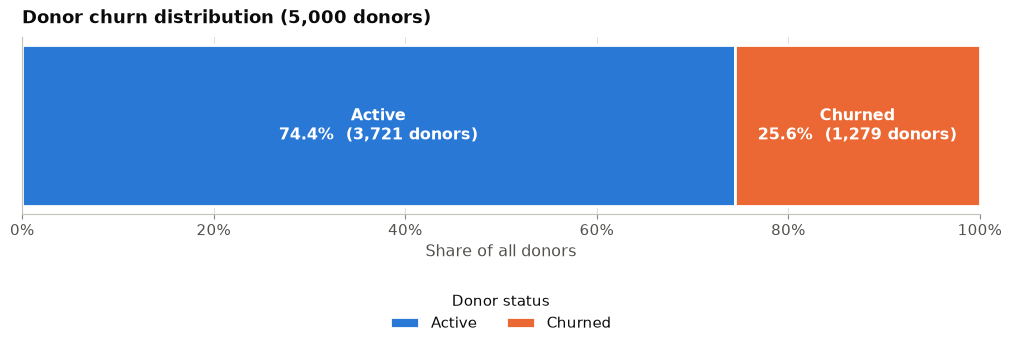

In [6]:
eda.plot_churn_distribution(df)

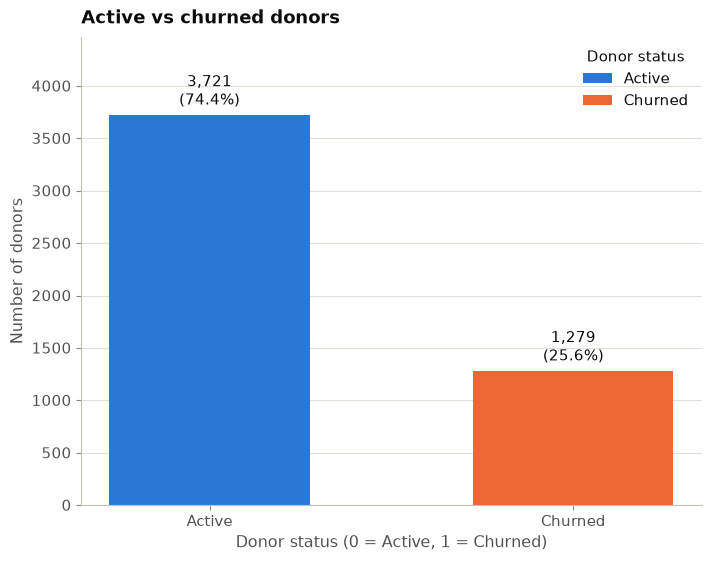

In [7]:
eda.plot_active_vs_churned(df)

## 4. Donation frequency

How often do donors give - monthly, quarterly or yearly - and does it relate to churn?

In [8]:
frequency_table = pd.DataFrame({
    "donors": df["donation_frequency"].value_counts(),
    "churn_rate": df.groupby("donation_frequency")[TARGET_COLUMN].mean(),
})
frequency_table

,donors,churn_rate
donation_frequency,,
Monthly,1721,0.11
Quarterly,1493,0.21
Yearly,1736,0.44


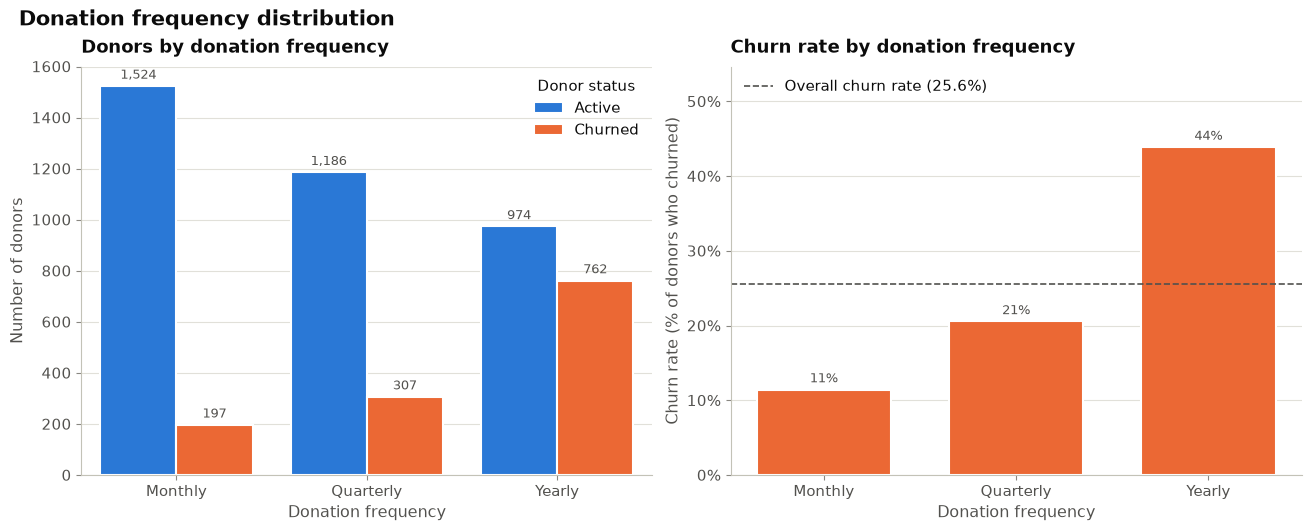

In [9]:
eda.plot_donation_frequency(df)

## 5. Donation amounts

Donation amounts are *right-skewed*: most donors give modest amounts and a few give a lot.
A log scale makes the shape easier to see.

In [10]:
summary["numeric_statistics"].loc[["avg_donation", "total_donated"]]

,count,mean,std,min,25%,50%,75%,max
avg_donation,"5,000.00",91.20,86.43,5.00,29.93,61.03,124.83,820.25
total_donated,"5,000.00",633.25,769.57,10.69,177.55,372.07,801.76,"12,452.23"


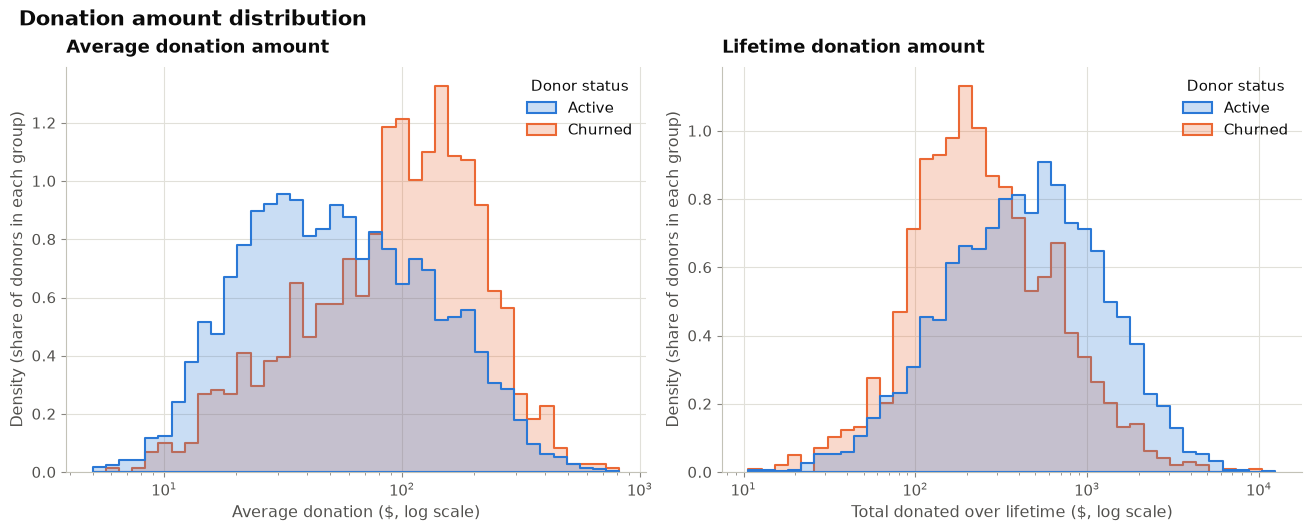

In [11]:
eda.plot_donation_amounts(df)

## 6. Donor age

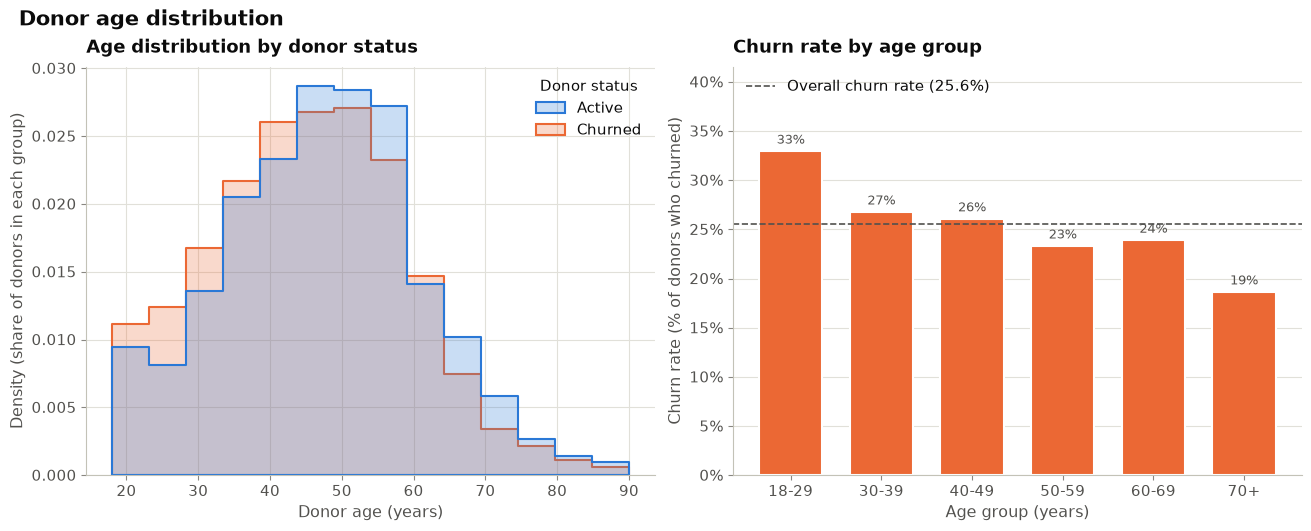

In [12]:
eda.plot_age_distribution(df)

## 7. Days since last donation (recency)

Recency is usually one of the strongest churn signals: the longer a donor has gone without giving,
the more likely they are to stop.

In [13]:
eda.churn_rate_by_bin(df, "days_since_last_donation", eda.RECENCY_BINS, eda.RECENCY_LABELS)

,band,churn_rate,donors
0,0-30,0.08,1687
1,31-90,0.19,1309
2,91-180,0.32,751
3,181-365,0.46,755
4,366-730,0.60,387
5,730+,0.73,111


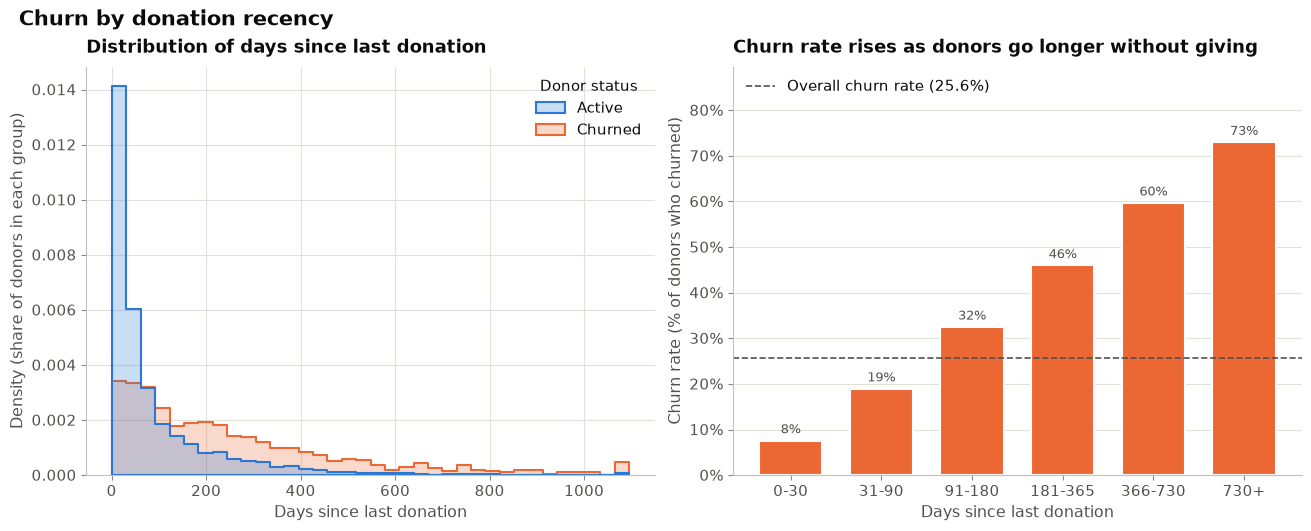

In [14]:
eda.plot_recency(df)

## 8. Engagement: email opens and campaign responses

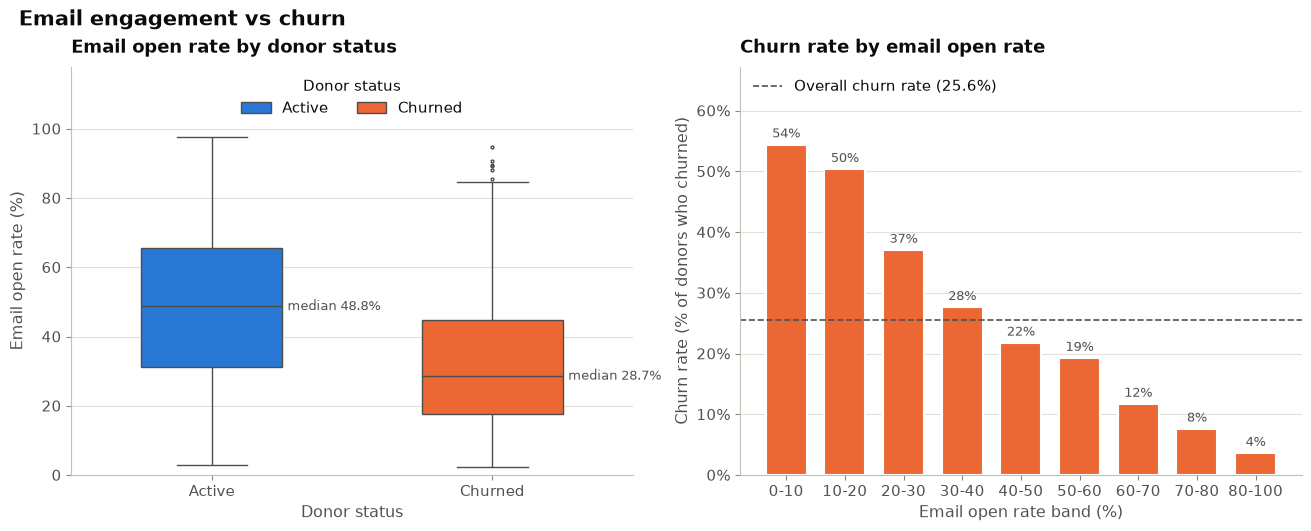

In [15]:
eda.plot_email_engagement(df)

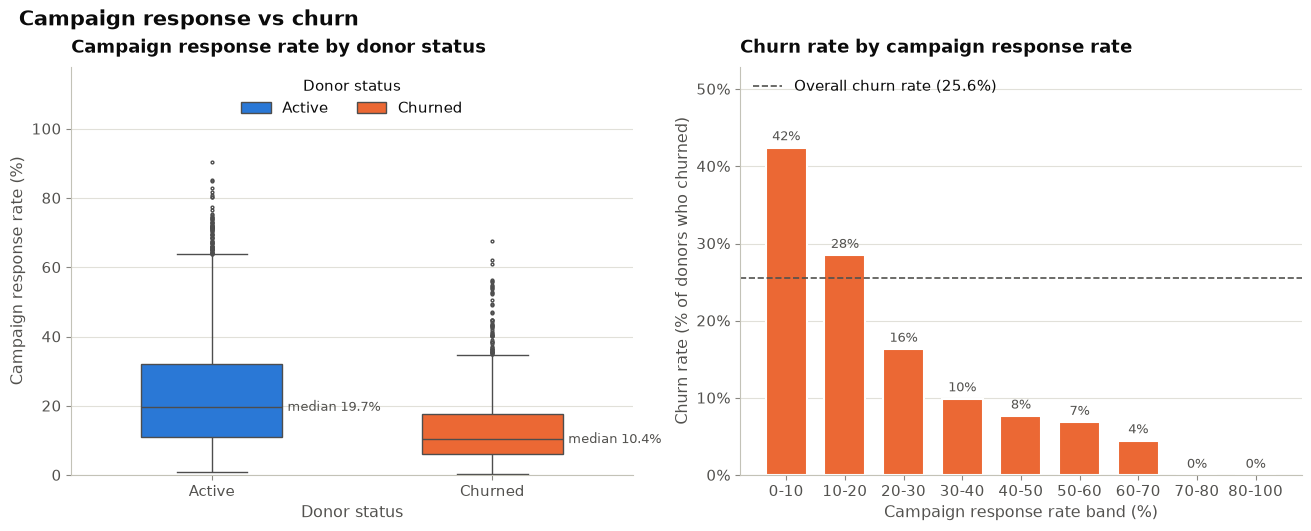

In [16]:
eda.plot_campaign_response(df)

## 9. Correlation between numerical variables

Correlation ranges from -1 to +1. Positive values with `churn` mean "higher value, more churn";
negative values mean "higher value, less churn". Correlation shows association, **not** causation.

In [17]:
summary["correlation_with_churn"].to_frame("correlation_with_churn")

,correlation_with_churn
email_open_rate,-0.33
campaign_response_rate,-0.29
recurring_donor,-0.27
donation_count,-0.24
total_donated,-0.17
age,-0.07
donor_tenure_months,-0.06
previous_churn_flag,0.08
avg_donation,0.21
days_since_last_donation,0.39


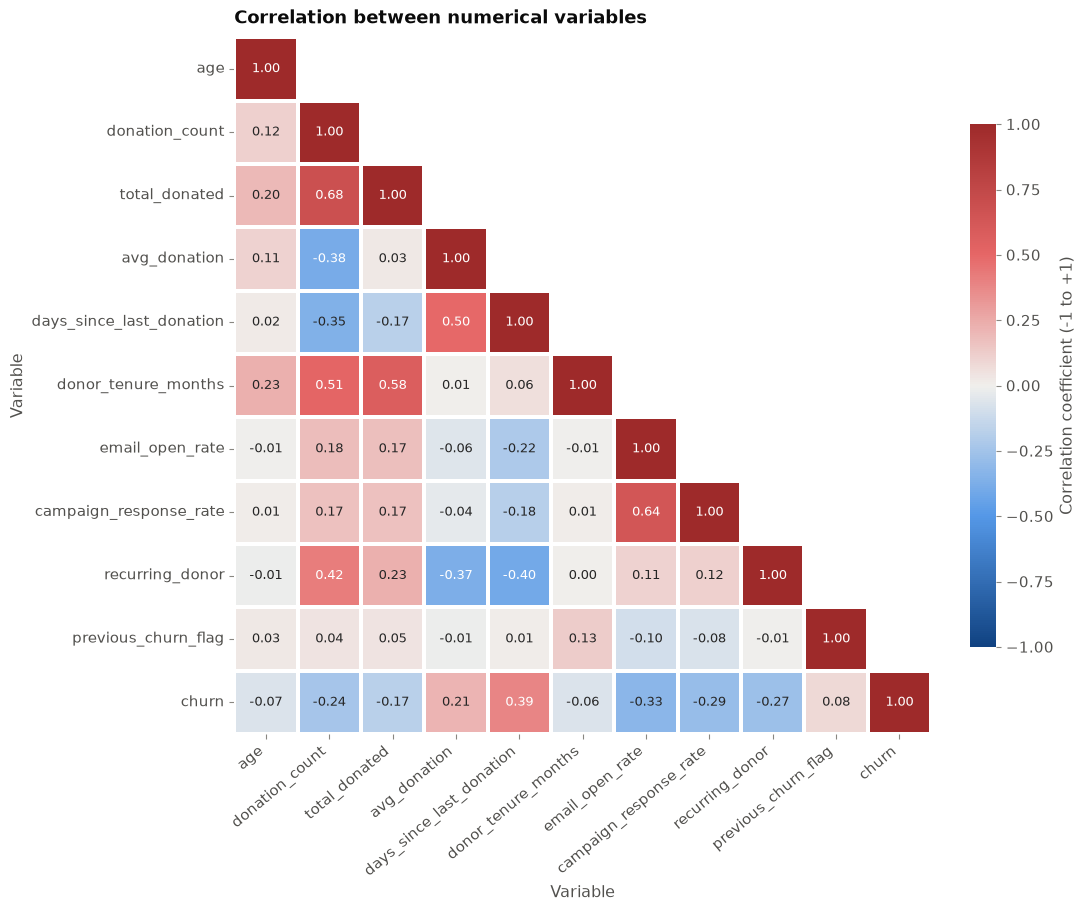

In [18]:
eda.plot_correlation_heatmap(df)

In [19]:
# Average value of each numeric feature for active vs churned donors
summary["means_by_status"]

churn,Active,Churned
age,47.41,45.24
donation_count,16.88,6.04
total_donated,711.65,405.14
avg_donation,80.34,122.82
days_since_last_donation,95.01,258.23
donor_tenure_months,43.12,38.68
email_open_rate,48.70,32.18
campaign_response_rate,23.25,13.32


## 10. Save every chart

This writes the same 300 DPI PNG files as `python -m src.eda` into `reports/figures/`.

In [20]:
saved = eda.run_eda(df)
for name in saved:
    print(name)

donor_churn_distribution.png
active_vs_churned_donors.png
donation_frequency.png
churn_by_donation_recency.png
donation_amount_distribution.png
email_engagement_vs_churn.png
campaign_response_vs_churn.png
donor_age_distribution.png
correlation_heatmap.png


## Key takeaways

* **Class imbalance:** roughly a quarter of donors churn, so accuracy alone can be misleading and the
  train/test split should be *stratified*.
* **Recency matters most:** churn rate climbs steadily as days since the last donation increase.
* **Engagement protects:** donors who open more emails and respond to more campaigns churn less.
* **Recurring and monthly donors churn less** than one-off yearly donors.
* **Watch for confounding:** `avg_donation` is *positively* correlated with churn only because yearly donors give
  larger single gifts *and* churn more. Correlation is not causation.
* Some features are correlated with each other (for example `donation_count`, `total_donated` and
  `donor_tenure_months`), which is normal and fine for a regularised Logistic Regression.

Next step: `python -m src.train` to build the model.